In [2]:
import json
json_path = "/source/ms/highlight/json/RwWx5pKS3eA.json"
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

In [3]:
from scipy.interpolate import interp1d
import numpy as np
def interpolate(start_seconds, intensity_scores):
    interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")
    total_duration_seconds = start_seconds[-1]
    new_time = np.arange(0, total_duration_seconds, 1)
    smoothed_intensity_scores = interpolation_function(new_time)

    # half_cut = int(len(smoothed_intensity_scores)/2)
    # smoothed_intensity_scores = smoothed_intensity_scores[:half_cut]
    smoothed_intensity_scores = interpolation_function(new_time)
    return new_time, smoothed_intensity_scores

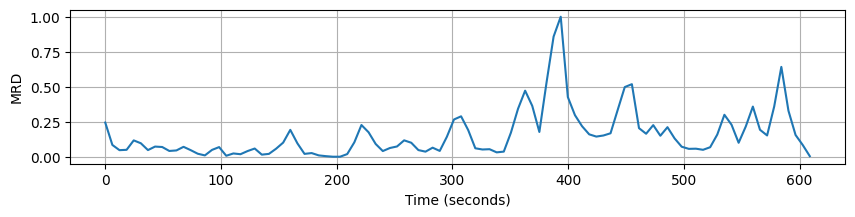

In [4]:
import matplotlib.pyplot as plt


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(10, 2))
plt.plot(start_seconds, intensity_scores)
# plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('MRD')
plt.grid(True)
plt.show()

In [5]:
new_time, intensity_scores = interpolate(start_seconds, intensity_scores)

In [6]:
import pickle
import os
dic = {}
ROOT = "./pickle"
for elem in os.listdir(ROOT):
    name = int(elem.split(".")[0])
    with open(f"{ROOT}/{elem}", 'rb') as f:
        print("import pickle!!!")
        dp_intervals, threshold_c, threshold_intervals, knapsack_intervals = pickle.load(f)
        dic[name] = dp_intervals

import pickle!!!
import pickle!!!
import pickle!!!
import pickle!!!


In [7]:
dic

{60: [(357, 368), (379, 402), (445, 458), (579, 588)],
 90: [(301, 308), (356, 370), (378, 405), (442, 459), (556, 563), (577, 589)],
 120: [(300, 310),
  (353, 373),
  (378, 407),
  (440, 460),
  (533, 541),
  (555, 564),
  (575, 592)],
 30: [(381, 398), (449, 456), (582, 585)]}

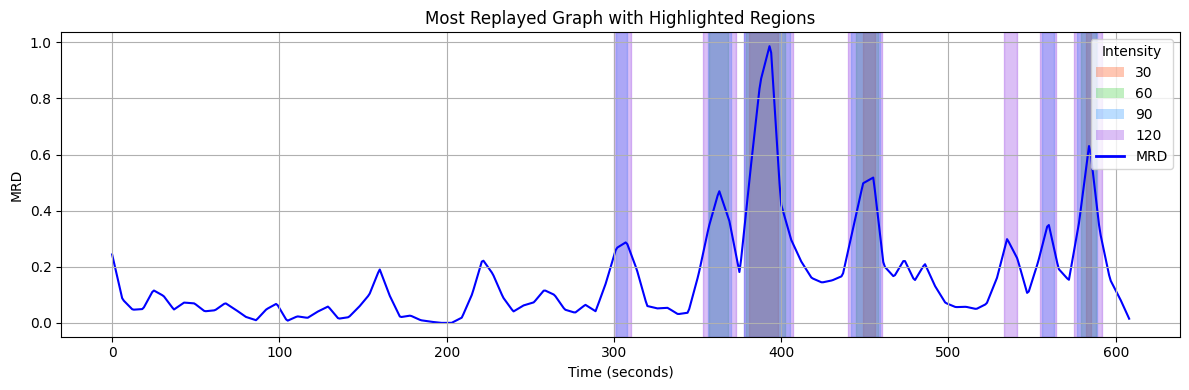

In [8]:

import numpy as np

# 그래프 생성
plt.figure(figsize=(12, 4))

# 하이라이트 그리기
colors = ['#FF4500', '#32CD32', '#1E90FF', '#8A2BE2']  # 진한 주황, 진한 라임, 진한 파랑, 진한 보라
sorted_keys = sorted(dic.keys())

for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        plt.axvspan(start, end, color=color, alpha=0.3, zorder=0)

# MRD 그래프 그리기
plt.plot(new_time, intensity_scores, color='blue', zorder=1)

plt.xlabel('Time (seconds)')
plt.ylabel('MRD')
plt.grid(True)
plt.title('Most Replayed Graph with Highlighted Regions')

# 범례 추가
legend_elements = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], alpha=0.3, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='blue', lw=2, label='MRD'))
plt.legend(handles=legend_elements, title='Intensity', loc='upper right')

plt.tight_layout()
plt.show()

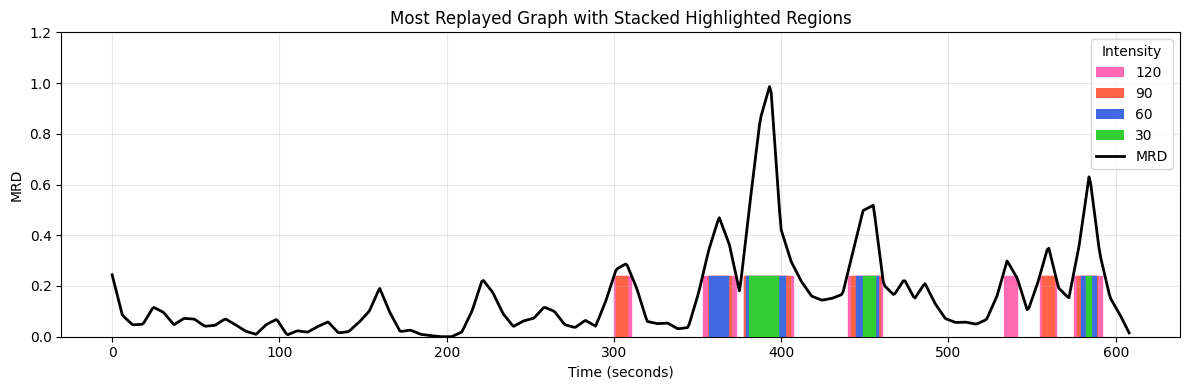

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# 주어진 딕셔너리
dic = {60: [(357, 368), (379, 402), (445, 458), (579, 588)],
       90: [(301, 308), (356, 370), (378, 405), (442, 459), (556, 563), (577, 589)],
       120: [(300, 310), (353, 373), (378, 407), (440, 460), (533, 541), (555, 564), (575, 592)],
       30: [(381, 398), (449, 456), (582, 585)]}


# 그래프 생성
fig, ax = plt.subplots(figsize=(12, 4))

# 색상 정의 (불투명)
colors = ['#FF69B4', '#FF6347', '#4169E1', '#32CD32']  # 분홍, 토마토, 로얄블루, 라임그린

# 강도 레벨을 역순으로 정렬 (30이 가장 위에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        ax.axvspan(start, end, ymin=0, ymax=0.2, color=color, alpha=1, zorder=i)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=2, zorder=len(sorted_keys))

ax.set_xlabel('Time (seconds)')
ax.set_ylabel('MRD')
ax.grid(True, alpha=0.3)
ax.set_title('Most Replayed Graph with Stacked Highlighted Regions')

# y축 범위 설정
ax.set_ylim(0, 1.2)

# 범례 추가
legend_elements = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))
ax.legend(handles=legend_elements, title='Intensity', loc='upper right')

plt.tight_layout()
plt.show()

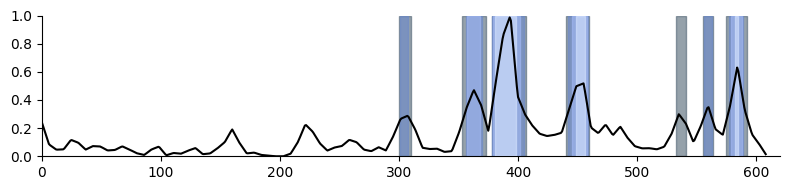

In [10]:
# 그래프 생성
fig, ax = plt.subplots(figsize=(8, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#4F6272', '#6A89CC', '#A3B9F5', '#D6E4FF'] 
# 강도 레벨을 역순으로 정렬 (30이 가장 위에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        ax.axvspan(start, end, ymin=0, ymax=1, color=color, alpha=0.6, zorder=i)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys))

# ax.set_xlabel('Time (seconds)')
# ax.set_ylabel('MRD')
ax.grid(True, alpha=0.3)
# ax.set_title('Most Replayed Graph with Stacked Highlighted Regions')

# y축 범위 설정
ax.set_ylim(0, 1)
ax.set_xlim(0, 620)
# ax.set_ylabel('Intensity')
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

# 범례 추가 (왼쪽에 위치)
legend_elements = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))
# ax.legend(handles=legend_elements[::-1], title='Intensity', loc='center left', bbox_to_anchor=(0.02, 0.5),
#           fontsize=10, title_fontsize=2)

plt.tight_layout()
plt.show()

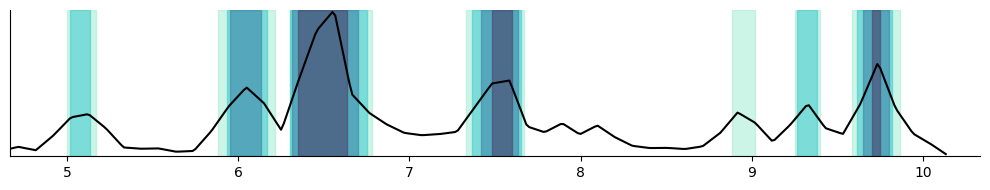

In [11]:
# 그래프 생성
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(10, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
colors.reverse()
# 강도 레벨을 역순으로 정렬 (30이 가장 위에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)
# sorted_keys = [sorted_keys[3]]

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        ax.axvspan(start, end, ymin=0, ymax=1, color=color, alpha=0.6, zorder=i)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys))

# ax.set_xlabel('Time (seconds)')
# ax.set_ylabel('MRD')
ax.grid(True, alpha=0.3)
# ax.set_title('Most Replayed Graph with Stacked Highlighted Regions')

# y축 범위 설정
ax.set_ylim(0, 1)
ax.set_xlim(280, 620)
# ax.set_ylabel('Intensity')
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))
# ax.legend(handles=legend_elements[::-1], title='Intensity', loc='center left', bbox_to_anchor=(0.02, 0.5),
#           fontsize=10, title_fontsize=2)

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    seconds = int(value % 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

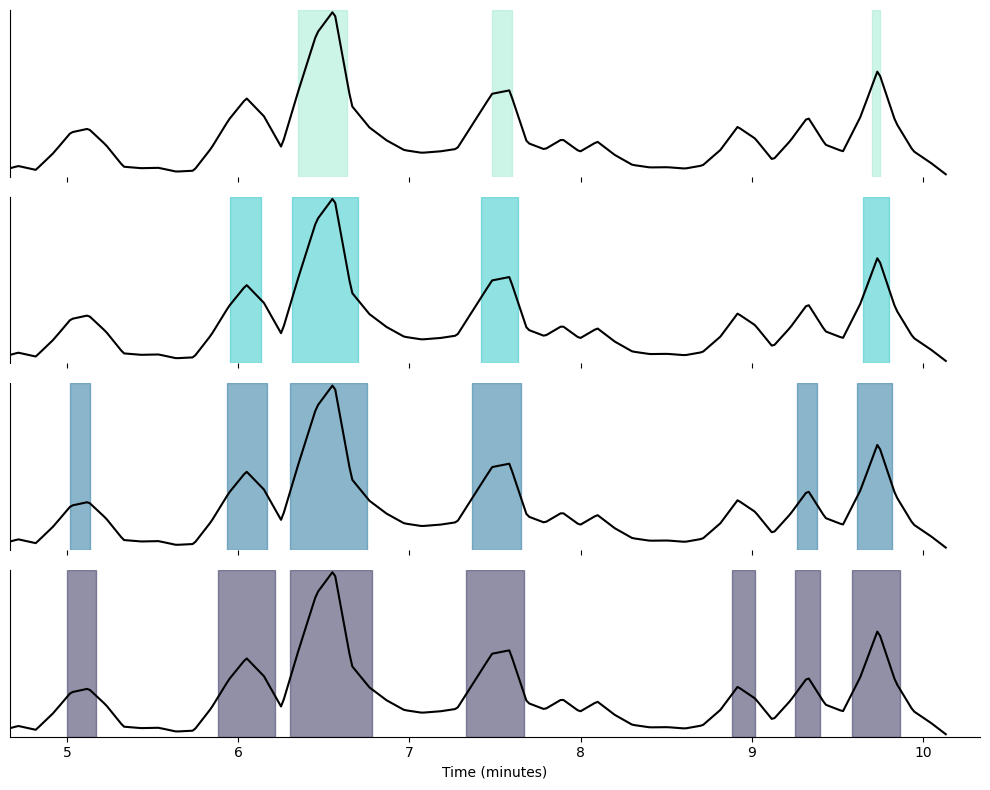

In [12]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 그래프 생성
fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
fig.subplots_adjust(hspace=0)

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
colors.reverse()
# 강도 레벨 순서 정의
intensity_levels = [30, 60, 90, 120]

for i, key in enumerate(intensity_levels):
    ax = axs[i]
    color = colors[i]
    
    # 하이라이트 그리기
    for start, end in dic[key]:
        ax.axvspan(start, end, ymin=0, ymax=1, color=color, alpha=0.6)

    # MRD 그래프 그리기
    ax.plot(new_time, intensity_scores, color='black', linewidth=1.5)

    # y축 범위 설정
    ax.set_ylim(0, 1)
    ax.set_xlim(280, 620)
    ax.grid(False)
    ax.spines['top'].set_color('none')
    ax.spines['right'].set_color('none')
    ax.spines['bottom'].set_color('none')
    ax.yaxis.set_ticks([])
    
    # 강도 레벨 표시
    # ax.text(275, 0.5, f'{key}', va='center', ha='right', fontsize=10)

    # 마지막 subplot에만 x축 표시
    if i == len(intensity_levels) - 1:
        ax.spines['bottom'].set_position('zero')
        ax.spines['bottom'].set_color('black')
    else:
        ax.xaxis.set_ticks([])

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    return f'{minutes}'

axs[-1].xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
axs[-1].xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시
axs[-1].set_xlabel('Time (minutes)')

plt.tight_layout()
plt.show()

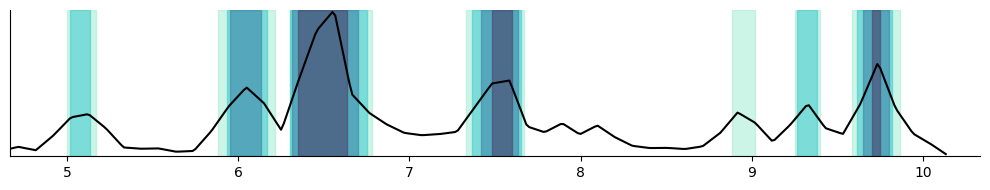

In [13]:
# 그래프 생성
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(10, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
colors.reverse()
# 강도 레벨을 역순으로 정렬 (30이 가장 위에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)
# sorted_keys = [sorted_keys[3]]

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        ax.axvspan(start, end, ymin=0, ymax=1, color=color, alpha=0.6, zorder=i)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys))

# ax.set_xlabel('Time (seconds)')
# ax.set_ylabel('MRD')
ax.grid(True, alpha=0.3)
# ax.set_title('Most Replayed Graph with Stacked Highlighted Regions')

# y축 범위 설정
ax.set_ylim(0, 1)
ax.set_xlim(280, 620)
# ax.set_ylabel('Intensity')
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))
# ax.legend(handles=legend_elements[::-1], title='Intensity', loc='center left', bbox_to_anchor=(0.02, 0.5),
#           fontsize=10, title_fontsize=2)

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    seconds = int(value % 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

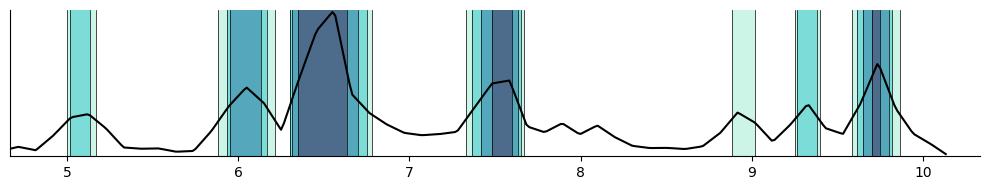

In [14]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
colors.reverse()

# 강도 레벨을 역순으로 정렬 (30이 가장 위에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    for start, end in dic[key]:
        # 색칠된 영역
        rect = Rectangle((start, 0), end - start, 1, 
                         facecolor=color, 
                         edgecolor='none',
                         alpha=0.6, 
                         zorder=i)
        ax.add_patch(rect)
        
        # 왼쪽 테두리
        ax.axvline(x=start, ymin=0, ymax=1, color='black', linewidth=0.5, zorder=i+0.1)
        # 오른쪽 테두리
        ax.axvline(x=end, ymin=0, ymax=1, color='black', linewidth=0.5, zorder=i+0.1)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys))

# y축 범위 설정
ax.set_ylim(0, 1)
ax.set_xlim(280, 620)
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [Rectangle((0, 0), 1, 1, fc=colors[i], ec='black', alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

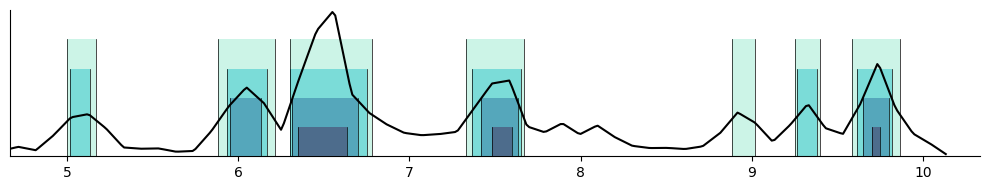

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
# colors.reverse()


# 강도 레벨을 역순으로 정렬 (120이 가장 아래에 오도록)
sorted_keys = sorted(dic.keys(), reverse=False)

# 높이 설정
heights = {30: 0.2, 60: 0.4, 90: 0.6, 120: 0.8}

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    height = heights[key]
    for start, end in dic[key]:
        # 색칠된 영역
        rect = Rectangle((start, 0), end - start, height, 
                         facecolor=color, 
                         edgecolor='none',
                         alpha=0.6, 
                         zorder=len(sorted_keys) - i)  # zorder를 역순으로 설정
        ax.add_patch(rect)
        
        # 왼쪽 테두리
        ax.axvline(x=start, ymin=0, ymax=height, color='black', linewidth=0.5, zorder=len(sorted_keys) - i + 0.1)
        # 오른쪽 테두리
        ax.axvline(x=end, ymin=0, ymax=height, color='black', linewidth=0.5, zorder=len(sorted_keys) - i + 0.1)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys) + 1)

# y축 범위 설정
ax.set_ylim(0, 1)
ax.set_xlim(280, 620)
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [Rectangle((0, 0), 1, heights[key], fc=colors[i], ec='black', alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

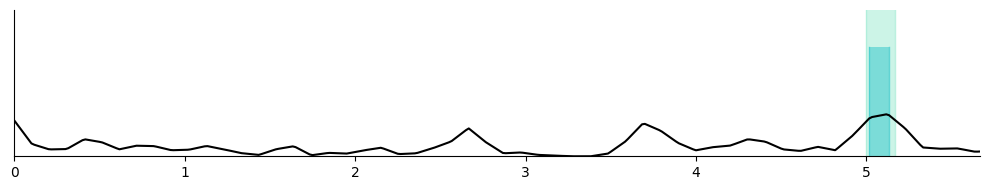

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 2))

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']

# 강도 레벨을 정렬 (30이 가장 아래에 오도록)
sorted_keys = sorted(dic.keys())

# 높이 설정 (120이 1.0, 즉 그래프 전체 높이가 되도록 설정)
max_height = 1.0
heights = {30: 0.25 * max_height, 60: 0.5 * max_height, 90: 0.75 * max_height, 120: max_height}

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    height = heights[key]
    for start, end in dic[key]:
        # 색칠된 영역
        rect = Rectangle((start, 0), end - start, height, 
                         facecolor=color, 
                         edgecolor='none',
                         alpha=0.6, 
                         zorder=len(sorted_keys) - i)  # zorder를 역순으로 설정
        ax.add_patch(rect)
        
        # 왼쪽 테두리
        ax.axvline(x=start, ymin=0, ymax=height, color=color, linewidth=1, zorder=len(sorted_keys) - i + 0.1, alpha=0.8)
        # 오른쪽 테두리
        ax.axvline(x=end, ymin=0, ymax=height, color=color, linewidth=1, zorder=len(sorted_keys) - i + 0.1, alpha=0.8)

# MRD 그래프 그리기
ax.plot(new_time, intensity_scores, color='black', linewidth=1.5, zorder=len(sorted_keys) + 1)

# y축 범위 설정
ax.set_ylim(0, max_height)
ax.set_xlim(0, 340)
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [Rectangle((0, 0), 1, heights[key], fc=colors[i], ec=colors[i], alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

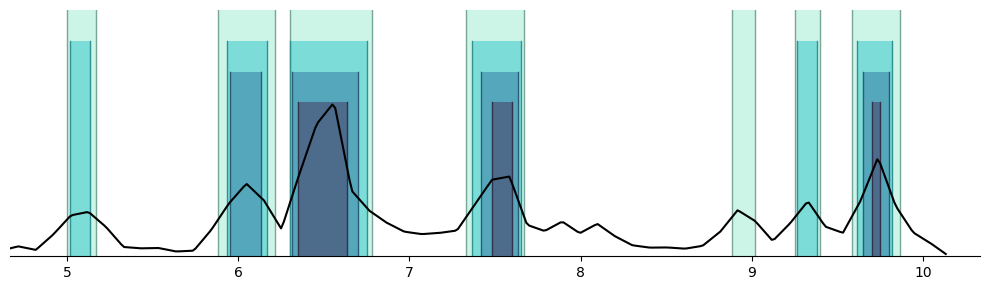

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors

def darken_color(color, factor=0.7):
    """주어진 색상을 어둡게 만듭니다."""
    rgb = mcolors.to_rgb(color)
    return tuple(max(0, min(1, c * factor)) for c in rgb)

# 그래프 생성
fig, ax = plt.subplots(figsize=(10, 3))  # 높이를 3으로 증가

# 색상 정의 (조화로운 색상 조합)
colors = ['#48466D', '#3D84A8', '#46CDCF', '#ABEDD8']
colors.reverse()
darker_colors = [darken_color(color) for color in colors]

# 강도 레벨을 정렬 (30이 가장 아래에 오도록)
sorted_keys = sorted(dic.keys(), reverse=True)

# 높이 설정 (30이 1.0, 즉 그래프 기본 높이가 되도록 설정)
base_height = 1.0
heights = {30: base_height, 60: base_height * 1.2, 90: base_height * 1.4, 120: base_height * 1.6}

# 하이라이트 그리기
for i, key in enumerate(sorted_keys):
    color = colors[i]
    darker_color = darker_colors[i]
    height = heights[key]
    for start, end in dic[key]:
        # 색칠된 영역
        rect = Rectangle((start, 0), end - start, height, 
                         facecolor=color, 
                         edgecolor='none',
                         alpha=0.6, 
                         zorder=i)  # zorder를 i로 설정하여 낮은 강도가 위에 오도록 함
        ax.add_patch(rect)
        
        # 왼쪽 테두리
        ax.axvline(x=start, ymin=0, ymax=height/base_height/1.6, color=darker_color, linewidth=1, zorder=i + 0.1, alpha=1)
        # 오른쪽 테두리
        ax.axvline(x=end, ymin=0, ymax=height/base_height/1.6, color=darker_color, linewidth=1, zorder=i + 0.1, alpha=1)

# MRD 그래프 그리기
ax.plot(new_time, [y * base_height for y in intensity_scores], color='black', linewidth=1.5, zorder=len(sorted_keys) + 1)

# y축 범위 설정
ax.set_ylim(0, base_height * 1.6)
ax.set_xlim(280, 620)
ax.grid(False)
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.spines['bottom'].set_position('zero')
ax.spines['left'].set_color('none')

ax.yaxis.set_ticks([])

# 범례 추가 (왼쪽에 위치)
legend_elements = [Rectangle((0, 0), 1, heights[key], fc=colors[i], ec=darker_colors[i], alpha=0.6, label=f'{key}') 
                   for i, key in enumerate(sorted_keys)]
legend_elements.append(plt.Line2D([0], [0], color='black', lw=2, label='MRD'))

# x축 눈금 설정
def format_func(value, tick_number):
    minutes = int(value / 60)
    return f'{minutes}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))  # 1분 간격으로 눈금 표시

plt.tight_layout()
plt.show()

# 여기 양궁

In [18]:
import json
json_path = "/source/ms/highlight/json/rzj4FFi7wt8.json"
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

In [19]:
from scipy.interpolate import interp1d
import numpy as np
def interpolate(start_seconds, intensity_scores):
    interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")
    total_duration_seconds = start_seconds[-1]
    new_time = np.arange(0, total_duration_seconds, 1)
    smoothed_intensity_scores = interpolation_function(new_time)

    # half_cut = int(len(smoothed_intensity_scores)/2)
    # smoothed_intensity_scores = smoothed_intensity_scores[:half_cut]
    smoothed_intensity_scores = interpolation_function(new_time)
    return new_time, smoothed_intensity_scores
import matplotlib.pyplot as plt


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]



No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


ValueError: 138 is not in list

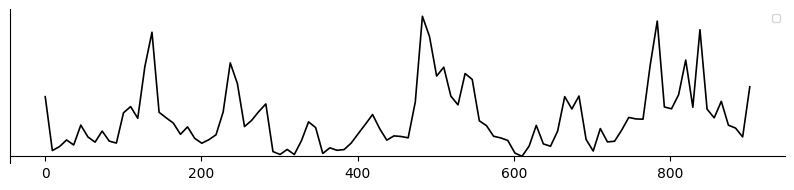

In [21]:
# 그래프 그리기
plt.figure(figsize=(10, 2))
a_include= [138, 162, 186, 344, 458, 489, 601, 755]
b_include = [172, 443, 565, 589, 767]
plt.grid(False)
plt.gca().spines['top'].set_color('none')
plt.gca().spines['right'].set_color('none')
plt.gca().spines['bottom'].set_position('zero')
# plt.gca().spines['left'].set_color('none')
plt.gca().yaxis.set_ticks([])
plt.plot(start_seconds, intensity_scores, color = "black",linewidth = 1.2)
# plt.title(f'Most Replayed Graph - Video ID: {video_id}')
# plt.xticks( fontsize=14)
plt.legend(fontsize=7)

# plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(format_func))
# plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(180))  # 1분 간격으로 눈금 표시

plt.show()